# Pre-entrega 4 — Aprendizaje no supervisado: perfiles de pozos

**Proyecto:** Análisis y predicción del rendimiento productivo en pozos de petróleo y gas de Argentina
**Programa:** EnergIA Digital — Data Science (Fundación YPF)
**Integrantes:** Mariapia Ortiz y Antonella Fontanetto
**Comisión:** 2

## Objetivo

En el notebook 02 predijimos la producción a partir de las características del pozo. Ahora hacemos la pregunta
al revés: **sin decirle al modelo qué tipo de pozo es**, ¿los pozos se agrupan solos según cómo producen?

Agrupamos cada pozo por su **perfil productivo de 2025** (cuánto petróleo y gas da por día, cuánta agua sale con
el petróleo y a qué profundidad está) con dos algoritmos vistos en clase, **K-Means** y **DBSCAN**. Después
comparamos los grupos con variables que el modelo no vio (tipo de recurso, cuenca, sistema de extracción) para
ver si tienen sentido.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. De pozo-mes a pozo

El dataset del notebook 01 tiene una fila por **pozo y mes**. Para agrupar pozos necesitamos **una fila por pozo**,
así que sumamos el año. Acá, a diferencia del notebook 02, sí podemos usar el gas y el agua: no hay nada que
predecir, así que no hay fuga de información. Queremos describir cómo produce cada pozo con todo lo que se midió.


In [2]:
pet = pd.read_csv("../data/processed/pozos_petroleros_2025.csv.gz")

pozos = pet.groupby("idpozo").agg(
    prod_pet=("prod_pet", "sum"), prod_gas=("prod_gas", "sum"), prod_agua=("prod_agua", "sum"),
    tef=("tef", "sum"), meses=("mes", "count"), profundidad=("profundidad", "first"),
    tipo_de_recurso=("tipo_de_recurso", "first"), cuenca=("cuenca", "first"),
    tipoextraccion=("tipoextraccion", "first"), empresa=("empresa", "first"),
)
print(f"{len(pozos):,} pozos")

24,388 pozos


Con las sumas armamos cuatro variables que describen el perfil del pozo:

| Variable | Qué mide |
|---|---|
| `caudal_pet` | m³ de petróleo por día efectivo (`prod_pet / tef` del año) |
| `caudal_gas` | miles de m³ de gas por día efectivo |
| `corte_agua` | fracción de agua en el líquido extraído: `agua / (agua + petróleo)` |
| `profundidad` | profundidad del pozo, en metros |

Dividimos por los días efectivos para comparar pozos que trabajaron distinta cantidad de días.

Sacamos tres grupos de pozos, porque sus variables no se pueden calcular: los que no registraron días efectivos
en todo el año, los que no produjeron petróleo y los que no tienen profundidad cargada (el mismo faltante que
vimos en el notebook 01).


In [3]:
validos = (pozos["tef"] > 0) & (pozos["prod_pet"] > 0) & pozos["profundidad"].notna()
print(f"Sin días efectivos o sin petróleo: {((pozos['tef'] <= 0) | (pozos['prod_pet'] <= 0)).sum():,}")
print(f"Sin profundidad (del resto): {(~validos & (pozos['tef'] > 0) & (pozos['prod_pet'] > 0)).sum():,}")
pozos = pozos[validos].copy()

pozos["caudal_pet"] = pozos["prod_pet"] / pozos["tef"]
pozos["caudal_gas"] = pozos["prod_gas"] / pozos["tef"]
pozos["corte_agua"] = pozos["prod_agua"] / (pozos["prod_agua"] + pozos["prod_pet"])

perfil = ["caudal_pet", "caudal_gas", "corte_agua", "profundidad"]
print(f"Quedan {len(pozos):,} pozos")
pozos[perfil].describe().T

Sin días efectivos o sin petróleo: 1,524
Sin profundidad (del resto): 1,638
Quedan 21,226 pozos


,count,mean,std,min,25%,50%,75%,max
caudal_pet,"21,226.00",6.91,22.21,0.00,0.81,1.62,3.48,417.13
caudal_gas,"21,226.00",1.25,5.61,0.00,0.00,0.08,0.37,202.94
corte_agua,"21,226.00",0.75,0.30,0.00,0.60,0.90,0.97,1.00
profundidad,"21,226.00","2,163.05","1,256.22",1.00,"1,330.25","1,966.50","2,501.00","7,922.00"


## 2. Preparación: logaritmo y escalado

Las dos buenas prácticas de K-Means y DBSCAN (clases 20 y 21) son **escalar** las variables, porque los dos
algoritmos usan distancias, y **cuidar los outliers**.

- Los caudales tienen la misma asimetría extrema que vimos en el notebook 01: la mediana del petróleo es 1,6
  m³/día y el máximo supera los 400. Sin transformar, los pocos pozos enormes dominarían las distancias. Les
  aplicamos `log1p`, igual que en el notebook 02.
- Después escalamos todo con `StandardScaler` (media 0, desvío 1), para que la profundidad, en miles de metros,
  no pese más que el corte de agua, que va de 0 a 1.


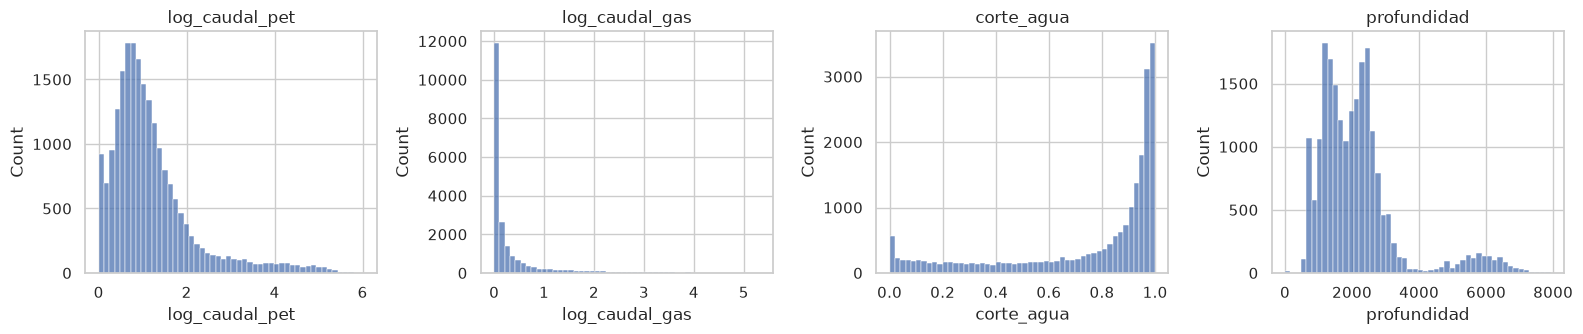

In [4]:
X = pd.DataFrame({
    "log_caudal_pet": np.log1p(pozos["caudal_pet"]),
    "log_caudal_gas": np.log1p(pozos["caudal_gas"]),
    "corte_agua": pozos["corte_agua"],
    "profundidad": pozos["profundidad"],
}, index=pozos.index)
X_esc = StandardScaler().fit_transform(X)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, X.columns):
    sns.histplot(X[col], bins=50, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Parte A — K-Means

## 3. ¿Cuántos grupos? Método del codo y silhouette

K-Means necesita que le digamos **k**, la cantidad de grupos. Usamos los dos criterios de la clase 22:

- **Método del codo:** la inercia (suma de distancias al cuadrado de cada pozo a su centroide) siempre baja al
  agregar grupos. Buscamos el k a partir del cual deja de bajar mucho.
- **Coeficiente de silhouette:** compara qué tan cerca está cada pozo de los de su grupo y qué tan lejos de los
  del grupo más cercano. Va de -1 a 1: más alto, grupos más compactos y separados.

Con `n_init=10` cada K-Means arranca 10 veces desde centroides distintos y se queda con el mejor (clase 20). El
silhouette compara cada pozo con todos los demás: con 21.000 pozos son 450 millones de distancias, así que lo
calculamos sobre una muestra al azar de 5.000 (`sample_size`).


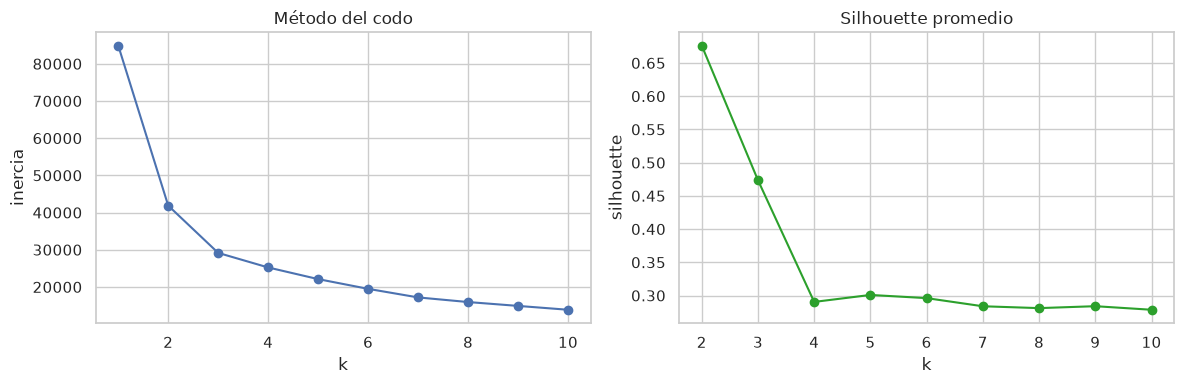

,inercia,baja respecto de k-1,silhouette
1,"84,904.00",NaN,NaN
2,"41,867.03","43,036.97",0.68
3,"29,155.23","12,711.80",0.47
4,"25,242.44","3,912.79",0.29
5,"22,109.66","3,132.78",0.30
6,"19,493.05","2,616.61",0.30
7,"17,189.02","2,304.03",0.28
8,"15,945.30","1,243.73",0.28
9,"14,904.87","1,040.43",0.28
10,"13,870.61","1,034.25",0.28


In [5]:
ks = range(1, 11)
inercias, siluetas = [], {}
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_esc)
    inercias.append(km.inertia_)
    if k >= 2:
        siluetas[k] = silhouette_score(X_esc, km.labels_, sample_size=5000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inercias, marker="o")
axes[0].set(title="Método del codo", xlabel="k", ylabel="inercia")
axes[1].plot(list(siluetas), list(siluetas.values()), marker="o", color="tab:green")
axes[1].set(title="Silhouette promedio", xlabel="k", ylabel="silhouette")
plt.tight_layout()
plt.show()

pd.DataFrame({"inercia": inercias, "baja respecto de k-1": -np.diff(inercias, prepend=np.nan),
              "silhouette": pd.Series(siluetas)}, index=ks).round(3)

**Criterio para elegir k.** Los dos métodos no dicen lo mismo, y eso es habitual:

- El **silhouette** es máximo en **k = 2** (≈ 0,68): hay dos grupos muy separados.
- El **codo** está en **k = 3**: de 2 a 3 grupos la inercia baja mucho (≈ 12.700); de 3 a 4, y de ahí en más,
  baja mucho menos (≈ 3.900 y ≈ 3.100). Agregar un cuarto grupo ya no ordena mucho más.

Elegimos **k = 3**. El tercer grupo, como vemos abajo, separa dentro de los convencionales a los pozos con poca
agua de los muy invadidos por agua, que es una diferencia con sentido operativo. Y su silhouette (≈ 0,47) sigue
indicando grupos razonablemente separados; desde k = 4 baja a alrededor de 0,30.


In [6]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_esc)
pozos["grupo_kmeans"] = kmeans.labels_
print(f"Silhouette (k=3): {silhouette_score(X_esc, kmeans.labels_, sample_size=5000, random_state=42):.3f}")

Silhouette (k=3): 0.474


## 4. ¿Qué es cada grupo?

Un grupo sólo sirve si se puede explicar. Miramos la **mediana** de cada variable por grupo, en sus unidades
originales (la mediana, porque los caudales son muy asimétricos).


In [7]:
def describir(columna):
    resumen = pozos.groupby(columna)[perfil].median()
    resumen.insert(0, "pozos", pozos[columna].value_counts())
    resumen["% del petróleo"] = pozos.groupby(columna)["prod_pet"].sum() / pozos["prod_pet"].sum() * 100
    return resumen


describir("grupo_kmeans")

,pozos,caudal_pet,caudal_gas,corte_agua,profundidad,% del petróleo
grupo_kmeans,,,,,,
0,15856,1.52,0.06,0.95,"1,893.00",30.41
1,1680,39.24,6.04,0.23,"5,789.00",62.20
2,3690,1.20,0.12,0.28,"1,690.50",7.39


In [8]:
nombres_kmeans = {}
resumen = describir("grupo_kmeans")
nombres_kmeans[resumen["caudal_pet"].idxmax()] = "No convencional de alto caudal"
resto = resumen.drop(index=list(nombres_kmeans))
nombres_kmeans[resto["corte_agua"].idxmax()] = "Convencional maduro, mucha agua"
nombres_kmeans[resto["corte_agua"].idxmin()] = "Convencional de bajo caudal, poca agua"
pozos["perfil"] = pozos["grupo_kmeans"].map(nombres_kmeans)
describir("perfil")

,pozos,caudal_pet,caudal_gas,corte_agua,profundidad,% del petróleo
perfil,,,,,,
"Convencional de bajo caudal, poca agua",3690,1.20,0.12,0.28,"1,690.50",7.39
"Convencional maduro, mucha agua",15856,1.52,0.06,0.95,"1,893.00",30.41
No convencional de alto caudal,1680,39.24,6.04,0.23,"5,789.00",62.20


Los tres grupos se leen así:

- **Convencional maduro, mucha agua:** la gran mayoría de los pozos. Producen poco petróleo por día y casi todo
  lo que sale es agua (corte cercano al 95 %). Es el perfil típico de un yacimiento viejo: con los años el agua
  invade la formación.
- **Convencional de bajo caudal, poca agua:** pozos de poca profundidad y caudal bajo, pero con mucha menos agua.
- **No convencional de alto caudal:** unos pocos pozos muy profundos (la profundidad incluye el tramo horizontal),
  con caudales decenas de veces mayores, más gas y poca agua. Son menos del 10 % de los pozos y dan **la mayor
  parte del petróleo del año**.

## 5. Validación externa: ¿coinciden con lo que sabemos de los pozos?

El modelo **no vio** el tipo de recurso, la cuenca ni el sistema de extracción. Si los grupos coinciden con esas
variables, es señal de que encontró algo real y no un artefacto.


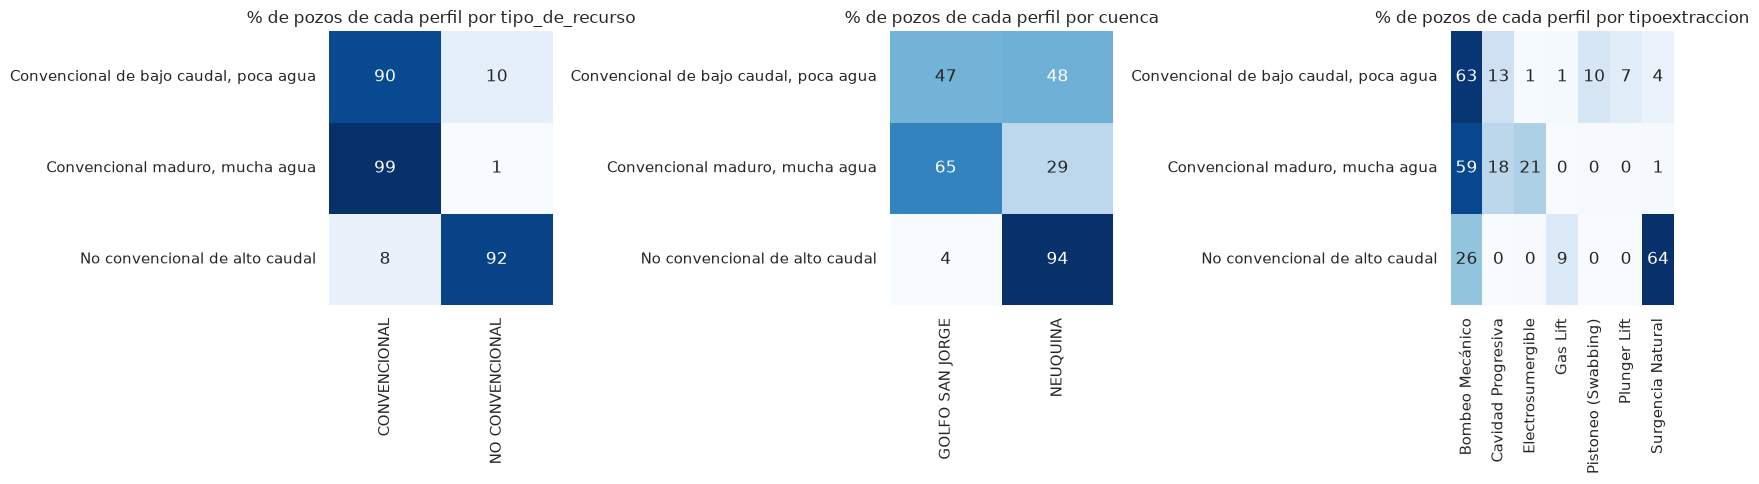

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col in zip(axes, ["tipo_de_recurso", "cuenca", "tipoextraccion"]):
    tabla = pd.crosstab(pozos["perfil"], pozos[col], normalize="index") * 100
    tabla = tabla.loc[:, tabla.max() >= 5]
    sns.heatmap(tabla, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=ax)
    ax.set(title=f"% de pozos de cada perfil por {col}", xlabel="", ylabel="")
    ax.tick_params(axis="x", labelrotation=90)
plt.tight_layout()
plt.show()

Lectura (los porcentajes son por fila: de cada perfil, cuántos pozos tiene cada categoría):

- El grupo de **alto caudal** es casi todo **no convencional** y de la **cuenca Neuquina**: K-Means redescubrió
  Vaca Muerta sólo mirando cómo producen los pozos.
- El convencional **con mucha agua** es sobre todo del **Golfo San Jorge** (65 %), la cuenca más antigua del país;
  el de **poca agua** se reparte mitad y mitad entre el Golfo San Jorge y la Neuquina.
- Casi dos de cada tres pozos de alto caudal son de **surgencia natural** (producen sin bomba, por la presión del
  reservorio); en los convencionales domina el **bombeo mecánico**.
- Las columnas con menos del 5 % de los pozos en todos los grupos no se muestran, para que el gráfico se lea.

## 6. Visualización con PCA

Tenemos cuatro variables, así que no podemos graficar los grupos directamente. Con **PCA** (clases 22 y 23)
las resumimos en dos componentes que conservan la mayor parte de la varianza, y graficamos los pozos en ese plano.


Varianza explicada por los 2 componentes: 83%


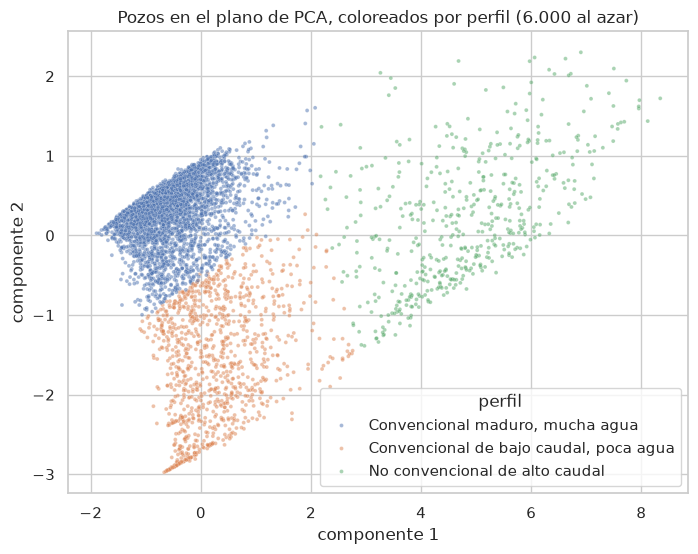

,log_caudal_pet,log_caudal_gas,corte_agua,profundidad
componente 1,0.53,0.54,-0.38,0.54
componente 2,0.32,0.12,0.92,0.21


In [10]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_esc)
print(f"Varianza explicada por los 2 componentes: {pca.explained_variance_ratio_.sum():.0%}")

muestra = np.random.default_rng(0).choice(len(X_pca), 6000, replace=False)
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=X_pca[muestra, 0], y=X_pca[muestra, 1], hue=pozos["perfil"].iloc[muestra],
                s=8, alpha=0.5, ax=ax)
ax.set(title="Pozos en el plano de PCA, coloreados por perfil (6.000 al azar)",
       xlabel="componente 1", ylabel="componente 2")
plt.show()

pd.DataFrame(pca.components_, columns=X.columns, index=["componente 1", "componente 2"]).round(2)

El grupo de alto caudal queda claramente aparte; los dos convencionales están pegados entre sí y se separan
a lo largo del segundo componente, donde pesa sobre todo el corte de agua. Por eso el silhouette era mejor con
k = 2: la frontera entre los dos convencionales es más difusa.

# Parte B — DBSCAN

## 7. Elección de los parámetros

DBSCAN no pide la cantidad de grupos, pero sí dos parámetros (clase 21):

- `min_samples`: cuántos vecinos necesita un punto para ser núcleo de un grupo. La regla de la clase es partir de
  **variables + 1 = 5**. Con 5, en una prueba, DBSCAN armaba decenas de grupos minúsculos de 4 a 25 pozos: con
  21.000 pozos, 5 vecinos es una densidad muy fácil de alcanzar. Lo subimos a **20**, para que un grupo tenga que
  ser realmente denso.
- `eps`: el radio de la vecindad. Graficamos, para cada pozo, la distancia a su vecino número 20, ordenada de
  menor a mayor, y buscamos el codo.


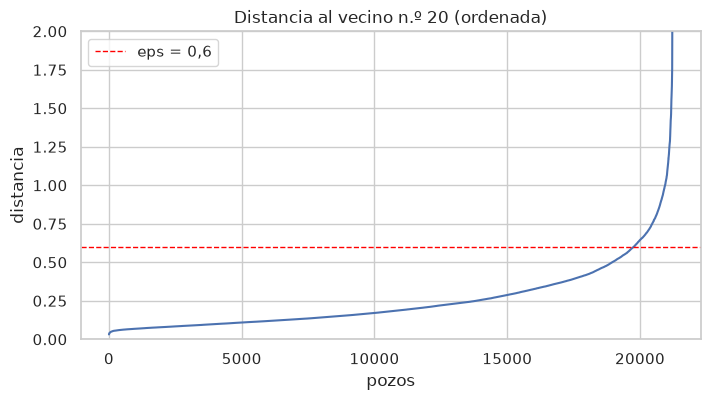

In [11]:
min_samples = 20
vecinos = NearestNeighbors(n_neighbors=min_samples).fit(X_esc)
distancia_k = np.sort(vecinos.kneighbors(X_esc)[0][:, -1])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(distancia_k)
ax.axhline(0.6, color="red", ls="--", lw=1, label="eps = 0,6")
ax.set(title=f"Distancia al vecino n.º {min_samples} (ordenada)", xlabel="pozos", ylabel="distancia", ylim=(0, 2))
ax.legend()
plt.show()

La curva crece despacio hasta cerca del 93–95 % de los pozos y ahí se dispara: ese es el codo, alrededor de
**0,6**.
Por encima de esa distancia están los pozos aislados, que DBSCAN va a marcar como ruido.


In [12]:
dbscan = DBSCAN(eps=0.6, min_samples=min_samples).fit(X_esc)
pozos["grupo_dbscan"] = dbscan.labels_
con_grupo = dbscan.labels_ != -1
print(f"Grupos: {dbscan.labels_.max() + 1} | ruido: {(~con_grupo).mean():.1%} de los pozos")
print(f"Silhouette sin el ruido: "
      f"{silhouette_score(X_esc[con_grupo], dbscan.labels_[con_grupo], sample_size=5000, random_state=42):.3f}")
describir("grupo_dbscan")

Grupos: 2 | ruido: 3.4% de los pozos


Silhouette sin el ruido: 0.701


,pozos,caudal_pet,caudal_gas,corte_agua,profundidad,% del petróleo
grupo_dbscan,,,,,,
-1,723,7.46,6.06,0.42,"2,900.00",10.49
0,19147,1.45,0.06,0.92,"1,845.00",35.69
1,1356,43.31,5.09,0.19,"5,843.50",53.83


## 8. K-Means contra DBSCAN


In [13]:
pd.crosstab(pozos["perfil"], pozos["grupo_dbscan"].map(lambda g: "ruido" if g == -1 else f"DBSCAN {g}"))

grupo_dbscan,DBSCAN 0,DBSCAN 1,ruido
perfil,,,
"Convencional de bajo caudal, poca agua",3412,11,267
"Convencional maduro, mucha agua",15735,0,121
No convencional de alto caudal,0,1345,335


In [14]:
ruido = pozos[pozos["grupo_dbscan"] == -1]
print(ruido["tipo_de_recurso"].value_counts(normalize=True).round(2))
ruido[perfil].median()

tipo_de_recurso
CONVENCIONAL      0.61
NO CONVENCIONAL   0.39
Name: proportion, dtype: float64


caudal_pet        7.46
caudal_gas        6.06
corte_agua        0.42
profundidad   2,900.00
dtype: float64

- DBSCAN encuentra **dos grupos**, los mismos que el silhouette de K-Means con k = 2: convencionales y no
  convencionales. No separa a los dos tipos de convencionales porque entre ellos no hay un hueco de baja densidad:
  se pasa de uno a otro de manera continua.
- Su aporte propio es el **ruido**: 723 pozos (3,4 %) que no se parecen a ningún grupo. Son combinaciones poco
  comunes: un caudal de petróleo intermedio (mediana 7,5 m³/día, entre un convencional y un no convencional) con
  tanto gas como un no convencional, y una profundidad intermedia. Casi 4 de cada 10 son no convencionales y entre
  todos dan el 10 % del petróleo. Son los primeros que conviene mirar uno por uno (¿datos mal cargados?, ¿pozos
  especiales?).
- Coincide con lo visto en la clase 21: K-Means sirve para **segmentar** en una cantidad de grupos que elegimos
  y es fácil de interpretar; DBSCAN, para encontrar los grupos "naturales" y **detectar outliers** sin decirle
  cuántos grupos buscar.

## 9. Conclusiones

**Qué respondimos.** Sí: sin conocer el tipo de pozo, sólo con cuatro variables de su producción de 2025, los
pozos se agrupan en perfiles que coinciden con lo que se sabe de la industria. El hallazgo más fuerte es la
separación entre **convencionales y no convencionales**: la marcan los dos algoritmos, el silhouette de K-Means y
la validación externa con el tipo de recurso y la cuenca.

**Criterio de elección.** Con K-Means elegimos **k = 3** por el método del codo y porque el tercer grupo tiene
lectura operativa (convencional con mucha o con poca agua), aceptando un silhouette menor que con k = 2 (0,47
contra 0,68). Con DBSCAN elegimos `eps` con el gráfico del vecino más cercano y subimos `min_samples` a 20 para
evitar microgrupos.

**Límites.**
- Usamos un solo año (2025). Un pozo nuevo y uno que está terminando su vida útil pueden caer en el mismo grupo;
  con más años se podría agregar la **declinación** del pozo, que probablemente separe mejor a los convencionales.
- Sacamos los pozos sin profundidad cargada; si faltan más en alguna provincia, ese grupo queda subrepresentado.
- La profundidad de los no convencionales incluye el tramo horizontal, así que no es comparable uno a uno con la
  de un pozo vertical.

**Cómo se conecta con el resto del proyecto.** El perfil podría sumarse como variable en el modelo supervisado del
notebook 02, pero se calcula con la producción del mismo año: sería fuga de información si se usa para predecir
ese año. Sirve, en cambio, para **describir el parque de pozos** y para priorizar qué revisar.
